# Gemma 3 1B IT: PKU-SafeRLHF paired existing responses



In [1]:
!pip -q install transformers==4.51.3 datasets==3.5.0 accelerate==1.6.0 huggingface_hub==0.30.2 sentencepiece==0.2.0 tqdm==4.67.1



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 110.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.7/57.7 kB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 161.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.2/491.2 kB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 354.7/354.7 kB 37.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 481.4/481.4 kB 44.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.5/78.5 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.9/183.9 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 127.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the

## Mount Drive and authenticate


In [2]:
from google.colab import drive
drive.mount("/content/drive")

from huggingface_hub import login, notebook_login

try:
    from google.colab import userdata
    HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = None

if HF_TOKEN:
    login(token=HF_TOKEN)
else:
    notebook_login()



## Configuration
No generation sampling settings apply to teacher-forced existing responses.


In [3]:
import gc
import json
import os
import platform
import random
import re
import time
import traceback
from collections import Counter
from decimal import Decimal, InvalidOperation
from pathlib import Path

import accelerate
import datasets as datasets_lib
import huggingface_hub
import numpy as np
import torch
import transformers
from datasets import load_dataset
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

torch.set_grad_enabled(False)

RUN_MODE = "full"
ALLOW_FULL_RUN = True
FORCE_SMOKE_REGENERATE = True
MODES = {"smoke": 1, "pilot": 20, "full": 5000}
if RUN_MODE not in MODES:
    raise ValueError(f"Unknown RUN_MODE: {RUN_MODE}")
if RUN_MODE == "full" and not ALLOW_FULL_RUN:
    raise RuntimeError("Set ALLOW_FULL_RUN = True for full collection.")
NUM_PAIRS = MODES[RUN_MODE]
REQUIRE_OPPOSITE_SAFETY = True
SAMPLE_POOL_SIZE = 5000
SAMPLE_SEED = 42
MODEL_ID = "google/gemma-3-1b-it"
DATASET_NAME = "PKU-Alignment/PKU-SafeRLHF"
DATASET_CONFIG = "default"
DATASET_SPLIT = "train"
# Original parent folder, with a dedicated subfolder for this experiment.
ORIGINAL_OUTPUT_ROOT = Path("/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean")
OUTPUT_ROOT = ORIGINAL_OUTPUT_ROOT / "pku_saferlhf_existing_responses"
ROOT = OUTPUT_ROOT / "response_token_positions" / (
    f"full_{NUM_PAIRS}_pairs" if RUN_MODE == "full" else RUN_MODE
)
RECORDS_DIR = ROOT / "records"
HIDDEN_DIR = ROOT / "raw_layer_outputs"
ERRORS_DIR = ROOT / "errors"
RECORDS_JSONL = ROOT / "records.jsonl"
MANIFEST_PATH = ROOT / "experiment_manifest.json"
SAMPLE_CACHE_DIR = OUTPUT_ROOT / "fixed_samples"

for path in (
    ROOT,
    RECORDS_DIR,
    HIDDEN_DIR,
    ERRORS_DIR,
    SAMPLE_CACHE_DIR,
):
    path.mkdir(parents=True, exist_ok=True)


RESPONSE_SEGMENTATION_SPEC = {
    "version": 1,
    "basis": "response_content_tokens",
    "indexing": "zero_based_half_open",
    "method": "floor_token_thirds",
    "boundary_rule": "[0, T // 3, (2 * T) // 3, T]",
    "label_scope": "whole_response",
}


def response_segmentation(token_count):
    """Describe positional thirds of the saved response states without slicing them."""
    token_count = int(token_count)
    if token_count < 0:
        raise ValueError("Response token count cannot be negative.")
    first = token_count // 3
    second = (2 * token_count) // 3
    ranges = {
        "early": [0, first],
        "middle": [first, second],
        "late": [second, token_count],
    }
    return {
        **RESPONSE_SEGMENTATION_SPEC,
        "ranges": ranges,
        "token_counts": {
            name: end - start for name, (start, end) in ranges.items()
        },
    }


def atomic_json(path, payload):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2)
        handle.write("\n")
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(tmp, path)


def atomic_jsonl(path, rows):
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w", encoding="utf-8") as handle:
        for row in rows:
            handle.write(json.dumps(row, ensure_ascii=False) + "\n")
        handle.flush()
        os.fsync(handle.fileno())
    os.replace(tmp, path)


print("Run mode:", RUN_MODE)
print("Expected prompt pairs:", NUM_PAIRS)
print("Expected existing responses:", 2 * NUM_PAIRS)
print("Output root:", ROOT)


print("V2 RESPONSE-ONLY: no prompt states, no terminal token")
assert "response_token_positions" in str(ROOT)


Run mode: full
Expected prompt pairs: 5000
Expected existing responses: 10000
Output root: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs
V2 RESPONSE-ONLY: no prompt states, no terminal token


## Fixed paired sample
Seed 42; distinct exact prompt texts; both responses retained.


In [4]:
import hashlib

dataset = load_dataset(DATASET_NAME, DATASET_CONFIG, split=DATASET_SPLIT)
DATASET_FINGERPRINT = str(dataset._fingerprint)
SAMPLE_FILE = SAMPLE_CACHE_DIR / (
    f"pku_saferlhf_{DATASET_CONFIG}_{DATASET_SPLIT}_opposite{int(REQUIRE_OPPOSITE_SAFETY)}"
    f"_seed{SAMPLE_SEED}_n{SAMPLE_POOL_SIZE}_{DATASET_FINGERPRINT[:12]}.jsonl"
)
# if SAMPLE_FILE.exists():
#     sample_pool = [json.loads(line) for line in SAMPLE_FILE.read_text().splitlines() if line.strip()]
if SAMPLE_FILE.exists():
    with SAMPLE_FILE.open("r", encoding="utf-8") as handle:
        sample_pool = [
            json.loads(line) for line in handle if line.strip()
        ]
else:
    sample_pool, seen_prompts = [], set()
    for source_index in np.random.default_rng(SAMPLE_SEED).permutation(len(dataset)):
        row = dataset[int(source_index)]
        labels = [row["is_response_0_safe"], row["is_response_1_safe"]]
        if not all(isinstance(label, bool) for label in labels):
            raise TypeError("Expected boolean absolute safety labels.")
        if REQUIRE_OPPOSITE_SAFETY and labels[0] == labels[1]:
            continue
        if not all(isinstance(row[field], str) and row[field].strip()
                   for field in ("prompt", "response_0", "response_1")):
            continue
        prompt_hash = hashlib.sha256(row["prompt"].encode("utf-8")).hexdigest()
        if prompt_hash in seen_prompts:
            continue
        seen_prompts.add(prompt_hash)
        sample_pool.append({
            **row, "pair_id": f"s{len(sample_pool):04d}", "prompt_id": prompt_hash,
            "source_index": int(source_index), "source_split": DATASET_SPLIT,
            "dataset_fingerprint": DATASET_FINGERPRINT, "sample_seed": SAMPLE_SEED,
            "require_opposite_safety": REQUIRE_OPPOSITE_SAFETY,
        })
        if len(sample_pool) == SAMPLE_POOL_SIZE:
            break
    if len(sample_pool) != SAMPLE_POOL_SIZE:
        raise RuntimeError(f"Only {len(sample_pool)} eligible unique prompts; reduce SAMPLE_POOL_SIZE and full count.")
    atomic_jsonl(SAMPLE_FILE, sample_pool)
if len(sample_pool) != SAMPLE_POOL_SIZE or len({r["prompt_id"] for r in sample_pool}) != SAMPLE_POOL_SIZE:
    raise RuntimeError("Invalid cached pair count or duplicate prompts.")
for index, row in enumerate(sample_pool):
    if (row["pair_id"] != f"s{index:04d}" or row["source_split"] != DATASET_SPLIT
        or row["dataset_fingerprint"] != DATASET_FINGERPRINT or row["sample_seed"] != SAMPLE_SEED
        or row["require_opposite_safety"] != REQUIRE_OPPOSITE_SAFETY):
        raise RuntimeError("Cached sample metadata mismatch.")
    if REQUIRE_OPPOSITE_SAFETY and row["is_response_0_safe"] == row["is_response_1_safe"]:
        raise RuntimeError("Cached pair does not have opposite safety labels.")
pairs = sample_pool[:NUM_PAIRS]
samples = []
for pair in pairs:
    for response_id in (0, 1):
        samples.append({
            "sample_id": pair["pair_id"], "pair_id": pair["pair_id"],
            "prompt_id": pair["prompt_id"], "response_id": response_id,
            "source_index": pair["source_index"], "source_split": pair["source_split"],
            "dataset_fingerprint": DATASET_FINGERPRINT, "sample_seed": SAMPLE_SEED,
            "prompt": pair["prompt"], "response": pair[f"response_{response_id}"],
            "is_safe": pair[f"is_response_{response_id}_safe"],
            "paired_is_safe": pair[f"is_response_{1-response_id}_safe"],
            "category": pair.get(f"response_{response_id}_harm_category"),
            "severity_level": pair.get(f"response_{response_id}_severity_level"),
            "prompt_source": pair.get("prompt_source"),
            "response_source_model": pair.get(f"response_{response_id}_source"),
            "response_sha256": pair.get(f"response_{response_id}_sha256"),
            "better_response_id": pair.get("better_response_id"),
            "safer_response_id": pair.get("safer_response_id"),
        })
print("Prompt pairs:", len(pairs), "Responses:", len(samples))
print("Absolute safety labels:", dict(Counter("safe" if r["is_safe"] else "unsafe" for r in samples)))
print("Fixed sample pool:", SAMPLE_FILE)


Prompt pairs: 5000 Responses: 10000
Absolute safety labels: {'unsafe': 5000, 'safe': 5000}
Fixed sample pool: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/fixed_samples/pku_saferlhf_default_train_opposite1_seed42_n5000_692e7fc141f6.jsonl


## Load Gemma
Same model, dtype selection, eager attention, evaluation mode, and raw final-layer hook as the original notebook.


In [5]:
if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime in Colab.")

MODEL_DTYPE = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    torch_dtype=MODEL_DTYPE,
    device_map="auto",
    low_cpu_mem_usage=True,
    attn_implementation="eager",
)
model.eval()

if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token

if not hasattr(model, "model"):
    raise RuntimeError("Loaded model has no model.model backbone.")
backbone = model.model
backbone.eval()
if not hasattr(backbone, "norm"):
    raise RuntimeError(
        "Gemma backbone has no model-level final RMSNorm."
    )

text_config = getattr(model.config, "text_config", model.config)
NUM_LAYERS = int(text_config.num_hidden_layers)
HIDDEN_SIZE = int(text_config.hidden_size)
if (NUM_LAYERS, HIDDEN_SIZE) != (26, 1152):
    raise RuntimeError(
        "Expected Gemma 3 1B text shape (26, 1152), "
        f"found ({NUM_LAYERS}, {HIDDEN_SIZE})."
    )

MODEL_DEVICE = model.get_input_embeddings().weight.device
BACKBONE_DEVICE = next(backbone.parameters()).device

END_OF_TURN_ID = tokenizer.convert_tokens_to_ids(
    "<end_of_turn>"
)
if (
    END_OF_TURN_ID is None
    or END_OF_TURN_ID == tokenizer.unk_token_id
):
    raise RuntimeError(
        "Tokenizer has no valid <end_of_turn> token ID."
    )

configured_eos_ids = model.generation_config.eos_token_id
if configured_eos_ids is None:
    configured_eos_ids = []
elif isinstance(configured_eos_ids, int):
    configured_eos_ids = [configured_eos_ids]
else:
    configured_eos_ids = list(configured_eos_ids)

STOP_TOKEN_IDS = sorted(set(
    int(token_id)
    for token_id in [
        tokenizer.eos_token_id,
        END_OF_TURN_ID,
        *configured_eos_ids,
    ]
    if token_id is not None
))
ORDINARY_EOS_TOKEN_IDS = (
    set(STOP_TOKEN_IDS) - {END_OF_TURN_ID}
)


MODEL_REVISION = getattr(model.config, "_commit_hash", None)
TOKENIZER_REVISION = (
    getattr(tokenizer, "_commit_hash", None)
    or tokenizer.init_kwargs.get("_commit_hash")
)



## Response-token states only

The original prompt remains in the causal context. Save states at positions
`[P : P + T]`, where P is prompt length and T is the existing response's content
length. Row t represents response token t after processing that token. No prompt
position or appended terminal token is saved. This differs from the original
GSM8K next-token-prediction alignment, which started at the last prompt position.
Raw layer 26 is still captured before final RMSNorm.

Each record also includes `response_segmentation`: version 1, method
`floor_token_thirds`, with zero-based, half-open response-state ranges. For T
response-content tokens, boundaries are `[0, T // 3, (2 * T) // 3, T]`.
`ranges` contains `early`, `middle`, and `late`; `token_counts` records each
block's length. The original hidden-state array is retained in full.

These are relative response positions, not CoT reasoning phases. All three blocks
inherit the whole-response safety label; they are not independently annotated
safety spans. Empty and single-token blocks are retained. Analysis must handle
blocks too short for a chosen spectral estimate explicitly, especially centered
estimates, without dropping the whole response. Spectral metrics, length controls,
and alternative segmentations belong in analysis preprocessing.


In [6]:
def encode_existing_pair(sample):
    control_tokens = ("<start_of_turn>", "<end_of_turn>", "<bos>", "<eos>")
    if any(token in sample[field] for token in control_tokens for field in ("prompt", "response")):
        raise ValueError("Dataset text contains a reserved chat-control token.")
    rendered = tokenizer.apply_chat_template(
        [{"role": "user", "content": sample["prompt"]}],
        tokenize=False, add_generation_prompt=True,
    )
    prompt_ids = tokenizer(rendered, add_special_tokens=False, return_tensors="pt").input_ids[0].cpu()
    content_ids = tokenizer(sample["response"], add_special_tokens=False, return_tensors="pt").input_ids[0].cpu()
    if len(content_ids) == 0:
        raise ValueError("Response contains zero tokens.")
    response_ids = content_ids.clone()
    full_ids = tokenizer(rendered + sample["response"],
                         add_special_tokens=False, return_tensors="pt").input_ids[0].cpu()
    if not torch.equal(full_ids, torch.cat([prompt_ids, response_ids])):
        raise RuntimeError("Prompt/response token boundary is not independently tokenizable.")
    context_limit = int(text_config.max_position_embeddings)
    if len(full_ids) > context_limit:
        raise ValueError(f"Full pair has {len(full_ids)} tokens; context limit is {context_limit}. No truncation.")
    return prompt_ids, response_ids, len(content_ids)

@torch.inference_mode()
def replay_raw_causal_layers(
    prompt_input_ids,
    generated_ids,
):
    prompt_input_ids = prompt_input_ids.detach().cpu()
    generated_ids = generated_ids.detach().cpu()
    prompt_length = len(prompt_input_ids)
    generated_length = len(generated_ids)
    if prompt_length < 1 or generated_length < 1:
        raise ValueError(
            "Replay requires non-empty prompt and generation."
        )

    full_input_ids = torch.cat(
        [prompt_input_ids, generated_ids],
        dim=0,
    ).unsqueeze(0).to(BACKBONE_DEVICE)
    attention_mask = torch.ones_like(full_input_ids)

    captured = {
        "calls": 0,
        "raw_layer26": None,
    }

    def capture_pre_final_norm(_module, inputs):
        captured["calls"] += 1
        if not inputs:
            raise RuntimeError(
                "Final RMSNorm hook received no input."
            )
        captured["raw_layer26"] = (
            inputs[0][
                0,
                prompt_length:
                prompt_length + generated_length,
                :,
            ]
            .detach()
            .clone()
        )

    hook = backbone.norm.register_forward_pre_hook(
        capture_pre_final_norm
    )
    torch.cuda.synchronize()
    started = time.perf_counter()
    try:
        outputs = backbone(
            input_ids=full_input_ids,
            attention_mask=attention_mask,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True,
        )
        torch.cuda.synchronize()
    finally:
        hook.remove()
    replay_seconds = time.perf_counter() - started

    if captured["calls"] != 1:
        raise RuntimeError(
            "Final RMSNorm pre-hook did not run exactly once."
        )
    if outputs.hidden_states is None:
        raise RuntimeError(
            "Backbone did not return hidden states."
        )
    if len(outputs.hidden_states) != NUM_LAYERS + 1:
        raise RuntimeError(
            "Unexpected hidden-state tuple length: "
            f"{len(outputs.hidden_states)}."
        )

    raw_layer26 = captured["raw_layer26"]
    if raw_layer26 is None:
        raise RuntimeError(
            "Final RMSNorm pre-hook captured no tensor."
        )

    post_norm_final = outputs.hidden_states[-1][
        0,
        prompt_length:
        prompt_length + generated_length,
        :,
    ]
    reconstructed_post_norm = backbone.norm(
        raw_layer26.unsqueeze(0)
    )[0]
    tolerance = (
        2e-2
        if MODEL_DTYPE == torch.bfloat16
        else 2e-3
    )
    torch.testing.assert_close(
        reconstructed_post_norm,
        post_norm_final,
        rtol=tolerance,
        atol=tolerance,
    )
    max_abs_error = float(
        (
            reconstructed_post_norm.float()
            - post_norm_final.float()
        )
        .abs()
        .max()
        .item()
    )

    raw_layers_1_to_25 = torch.stack([
        state[
            0,
            prompt_length:
            prompt_length + generated_length,
            :,
        ]
        for state in outputs.hidden_states[1:-1]
    ])
    if raw_layers_1_to_25.shape[0] != 25:
        raise RuntimeError(
            "Expected raw outputs for layers 1-25."
        )

    raw_layers = torch.cat(
        [
            raw_layers_1_to_25,
            raw_layer26.unsqueeze(0),
        ],
        dim=0,
    )
    expected_shape = (
        NUM_LAYERS,
        generated_length,
        HIDDEN_SIZE,
    )
    if tuple(raw_layers.shape) != expected_shape:
        raise RuntimeError(
            f"Expected {expected_shape}, "
            f"found {tuple(raw_layers.shape)}."
        )

    raw_layers_cpu = (
        raw_layers
        .to(device="cpu", dtype=torch.float16)
        .numpy()
    )

    del outputs
    del raw_layer26
    del post_norm_final
    del reconstructed_post_norm
    del raw_layers_1_to_25
    del raw_layers
    del full_input_ids
    del attention_mask
    del captured

    return (
        raw_layers_cpu,
        replay_seconds,
        {
            "verified": True,
            "rtol": tolerance,
            "atol": tolerance,
            "max_abs_error": max_abs_error,
        },
    )



In [7]:
experiment_manifest = {
    "dataset": {"name": DATASET_NAME, "config": DATASET_CONFIG, "split": DATASET_SPLIT,
                "fingerprint": DATASET_FINGERPRINT, "seed": SAMPLE_SEED,
                "sample_pool_size": SAMPLE_POOL_SIZE, "sample_file": str(SAMPLE_FILE)},
    "collection": {"mode": RUN_MODE, "num_prompt_pairs": NUM_PAIRS, "num_responses": 2 * NUM_PAIRS,
                   "require_opposite_safety": REQUIRE_OPPOSITE_SAFETY,
                   "fresh_generation": False, "truncation": False,
                   "append_terminal_token": False,
                   "label_field": "is_safe", "label_source": "existing PKU-SafeRLHF safety annotations"},
    "model": {"id": MODEL_ID, "revision": MODEL_REVISION, "tokenizer_revision": TOKENIZER_REVISION,
              "dtype": str(next(model.parameters()).dtype), "attention": "eager", "use_cache": False},
    "hidden_states": {"shape": "[26, response_content_tokens, 1152]",
                      "dtype": "float16", "causal_slice": "[P : P + T]",
                      "layer_26": "raw decoder output before final RMSNorm"},
    "response_segmentation": dict(RESPONSE_SEGMENTATION_SPEC),
    "packages": {"transformers": transformers.__version__, "torch": torch.__version__,
                 "datasets": datasets_lib.__version__, "accelerate": accelerate.__version__},
}
if MANIFEST_PATH.exists():
    previous = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
    # Only the additive segmentation field may be migrated on existing runs.
    needs_segmentation_upgrade = "response_segmentation" not in previous
    if needs_segmentation_upgrade:
        previous["response_segmentation"] = experiment_manifest["response_segmentation"]
    if previous != experiment_manifest:
        raise RuntimeError("Existing manifest differs. Use a separate output subfolder for changed settings.")
    if needs_segmentation_upgrade:
        atomic_json(MANIFEST_PATH, previous)
else:
    atomic_json(MANIFEST_PATH, experiment_manifest)
print(f"Loaded {MODEL_ID}: {NUM_LAYERS} layers, width {HIDDEN_SIZE}")


Loaded google/gemma-3-1b-it: 26 layers, width 1152


## Atomic persistence and resume
JSON remains the commit marker. Each existing response has one artifact, without duplicate rollouts.
Resume still uses matching JSON/NPZ filenames. When `records.jsonl` is rebuilt,
completed records missing `response_segmentation` receive an atomic JSON-only
metadata update derived from `response_content_token_count`. Existing NPZ files
are never opened or rewritten for segmentation. Repeated rebuilds leave already
annotated record JSONs untouched. Legacy manifests receive only the additive
segmentation specification, after all other settings have been checked.


In [8]:
def artifact_paths(sample_id, rollout_id):
    key = f"{sample_id}_r{rollout_id:02d}"
    return (
        key,
        RECORDS_DIR / f"{key}.json",
        HIDDEN_DIR / f"{key}.npz",
    )


def artifact_key_sets():
    record_keys = {
        path.stem
        for path in RECORDS_DIR.glob("*.json")
    }
    hidden_keys = {
        path.stem
        for path in HIDDEN_DIR.glob("*.npz")
    }
    return record_keys, hidden_keys


def completed_artifact_keys():
    record_keys, hidden_keys = artifact_key_sets()
    return record_keys & hidden_keys


def validate_arrays_in_memory(arrays):
    required = {
        "causal_hidden_states",
        "prompt_token_ids",
        "generated_token_ids",
        "layer_indices",
        "layer_numbers",
    }
    if set(arrays) != required:
        raise RuntimeError(
            f"Unexpected NPZ array keys: {sorted(arrays)}"
        )

    hidden = arrays["causal_hidden_states"]
    prompt_ids = arrays["prompt_token_ids"]
    generated_ids = arrays["generated_token_ids"]
    layer_indices = arrays["layer_indices"]
    layer_numbers = arrays["layer_numbers"]

    expected_shape = (
        NUM_LAYERS,
        len(generated_ids),
        HIDDEN_SIZE,
    )
    if hidden.dtype != np.float16:
        raise RuntimeError(
            f"Hidden dtype must be float16, found {hidden.dtype}."
        )
    if hidden.shape != expected_shape:
        raise RuntimeError(
            f"Hidden shape must be {expected_shape}, "
            f"found {hidden.shape}."
        )
    if (
        prompt_ids.ndim != 1
        or prompt_ids.dtype != np.int64
        or len(prompt_ids) == 0
    ):
        raise RuntimeError(
            "prompt_token_ids must be a non-empty int64 vector."
        )
    if (
        generated_ids.ndim != 1
        or generated_ids.dtype != np.int64
        or len(generated_ids) == 0
    ):
        raise RuntimeError(
            "generated_token_ids must be a non-empty int64 vector."
        )
    if not np.array_equal(
        layer_indices,
        np.arange(NUM_LAYERS, dtype=np.int16),
    ):
        raise RuntimeError("layer_indices are not 0 through 25.")
    if not np.array_equal(
        layer_numbers,
        np.arange(1, NUM_LAYERS + 1, dtype=np.int16),
    ):
        raise RuntimeError("layer_numbers are not 1 through 26.")


def atomic_npz(path, arrays):
    validate_arrays_in_memory(arrays)
    path = Path(path)
    tmp = path.with_name(path.name + ".tmp.npz")
    np.savez(tmp, **arrays)
    with open(tmp, "rb+") as handle:
        os.fsync(handle.fileno())
    os.replace(tmp, path)


def rebuild_records_jsonl():
    # NPZ names only select committed keys; record data comes from JSON only.
    committed_keys = completed_artifact_keys()
    records = []
    for path in sorted(RECORDS_DIR.glob("*.json")):
        if path.stem not in committed_keys:
            continue
        with open(path, "r", encoding="utf-8") as handle:
            record = json.load(handle)
        if "response_segmentation" not in record:
            record["response_segmentation"] = response_segmentation(
                record["response_content_token_count"]
            )
            atomic_json(path, record)
        records.append(record)
    atomic_jsonl(RECORDS_JSONL, records)
    return records


def collect_one(sample):
    started = time.perf_counter()
    key, record_path, hidden_path = artifact_paths(sample["sample_id"], sample["response_id"])
    if record_path.exists():
        record_path.unlink()
    prompt_ids, response_ids, content_count = encode_existing_pair(sample)
    hidden, replay_seconds, norm_check = replay_raw_causal_layers(prompt_ids, response_ids)
    if not np.isfinite(hidden).all():
        raise RuntimeError("Non-finite hidden-state values.")
    arrays = {
        "causal_hidden_states": hidden,
        "prompt_token_ids": prompt_ids.numpy().astype(np.int64, copy=False),
        "generated_token_ids": response_ids.numpy().astype(np.int64, copy=False),
        "layer_indices": np.arange(NUM_LAYERS, dtype=np.int16),
        "layer_numbers": np.arange(1, NUM_LAYERS + 1, dtype=np.int16),
    }
    atomic_npz(hidden_path, arrays)
    record = {
        **sample, "rollout_id": sample["response_id"], "response_source": "existing_dataset_response",
        "label": int(sample["is_safe"]), "label_mapping": {"0": "unsafe", "1": "safe"},
        "label_source": "PKU-SafeRLHF existing per-response safety annotations",
        "prompt_token_count": len(prompt_ids), "response_token_count": len(response_ids),
        "response_content_token_count": content_count, "terminal_token_count": 0,
        "generated_token_count": len(response_ids),
        "generated_token_ids_semantics": "existing response content tokens only; not sampled",
        "response_content_range": [0, content_count],
        "response_segmentation": response_segmentation(content_count),
        "was_truncated": False, "hidden_state_npz": str(hidden_path),
        "hidden_state_shape": list(hidden.shape), "hidden_state_dtype": "float16",
        "layer_indices": list(range(NUM_LAYERS)), "layer_numbers": list(range(1, NUM_LAYERS + 1)),
        "causal_state_semantics": "row t is the raw decoder state at existing response token t, after processing that token",
        "causal_slice": "[P : P + T]",
        "layer_26_stage": "raw decoder block output before final RMSNorm",
        "raw_layer26_hook_verified": True, "final_rmsnorm_reconstruction": norm_check,
        "replay_seconds": round(replay_seconds, 6),
        "total_seconds": round(time.perf_counter() - started, 6),
    }
    atomic_json(record_path, record)
    return record


def run_collection():
    completed = completed_artifact_keys()
    stats = Counter()
    for index, sample in enumerate(tqdm(samples, desc=f"{RUN_MODE} existing-response collection")):
        key, _, _ = artifact_paths(sample["sample_id"], sample["response_id"])
        if key in completed:
            stats["skipped"] += 1
            continue
        try:
            collect_one(sample)
            stats["saved"] += 1
            (ERRORS_DIR / f"{key}.json").unlink(missing_ok=True)
        except Exception as exc:
            stats["failed"] += 1
            atomic_json(ERRORS_DIR / f"{key}.json", {
                "sample_id": sample["sample_id"], "response_id": sample["response_id"],
                "source_index": sample["source_index"],
                "exception_type": type(exc).__name__, "exception_message": str(exc),
                "traceback": traceback.format_exc(),
            })
            print(f"Failed {key}: {type(exc).__name__}: {exc}")
        finally:
            gc.collect()
            if (index + 1) % 10 == 0 or stats["failed"]:
                torch.cuda.empty_cache()
    return dict(stats)


## Run or resume

Each pair produces `sXXXX_r00` and `sXXXX_r01`, one NPZ + JSON per existing response.
Both share `pair_id` and `prompt_id`; `response_id` retains the original 0/1 order.
`is_safe` and `label` are absolute safety labels, independent of `safer_response_id`
(relative safety preference) and `better_response_id` (helpfulness preference).

NPZ `generated_token_ids` contains only existing response content tokens, retained
under this name for compatibility. Every saved hidden-state row corresponds to its
response token ID at the same index. All rows can be pooled; no terminal row is present.
Output uses `response_token_positions/` so earlier alignment outputs stay separate.
Split downstream data by `prompt_id` to keep both responses together.
JSON is the commit marker; reruns skip completed responses and retry incomplete ones.

For block analysis, read a record's `response_segmentation` and slice the saved
array directly with `hidden[:, start:end, :]`. For example:

```python
segmentation = record["response_segmentation"]
start, end = segmentation["ranges"]["early"]
early_states = hidden[:, start:end, :]
early_token_count = segmentation["token_counts"]["early"]
```

The complete array remains available for whole-response analysis. Short blocks
are recorded as-is; apply an explicit minimum-length policy for each analysis
metric. An empty or single-token block need not support a meaningful centered
spectral estimate. Existing completed records are backfilled when this index is
rebuilt, without rerunning inference or loading any NPZ arrays. Smoke mode's
existing `FORCE_SMOKE_REGENERATE` setting still controls deliberate re-extraction;
set it to `False` when resuming an existing smoke run.


In [9]:
# %run -i /content/pku_saferlhf_token_boundary_fix.py

In [10]:
if RUN_MODE == "smoke" and FORCE_SMOKE_REGENERATE:
    for sample in samples:
        _, path, _ = artifact_paths(sample["sample_id"], sample["response_id"])
        path.unlink(missing_ok=True)
COLLECTION_STATS = run_collection()
records = rebuild_records_jsonl()
print("Collection:", COLLECTION_STATS)
print("Committed responses:", len(records))
print("Safety labels:", dict(Counter("safe" if r["is_safe"] else "unsafe" for r in records)))
print("records.jsonl:", RECORDS_JSONL)
print("Hidden-state directory:", HIDDEN_DIR)
if COLLECTION_STATS.get("failed", 0) or len(records) != 2 * NUM_PAIRS:
    raise RuntimeError("Collection is incomplete. Inspect errors and rerun to resume.")
if RUN_MODE == "smoke":
    print("Smoke extraction passed. Set RUN_MODE = 'full' to collect 1,000 prompt pairs / 2,000 existing responses.")

for record in records:
    assert record["terminal_token_count"] == 0, "Old terminal-token configuration!"
    assert record["causal_slice"] == "[P : P + T]", "Old alignment!"
    assert record["hidden_state_shape"][1] == record["response_content_token_count"]
    assert "response_token_positions" in record["hidden_state_npz"]
print("V2 response-position checks PASSED")


Collection: {'skipped': 10000}
Committed responses: 10000
Safety labels: {'unsafe': 5000, 'safe': 5000}
records.jsonl: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/records.jsonl
Hidden-state directory: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/raw_layer_outputs
V2 response-position checks PASSED


In [11]:
from IPython.display import display, HTML
import html

for pair in sample_pool[:10]:
    display(HTML(
        f"<h3>{html.escape(pair['pair_id'])}</h3>"
        f"<b>Prompt:</b> {html.escape(pair['prompt'])}"
    ))

    for rid in (0, 1):
        safe = pair[f"is_response_{rid}_safe"]
        categories = pair.get(f"response_{rid}_harm_category") or {}
        flagged = ", ".join(k for k, v in categories.items() if v)
        color = "#176b35" if safe else "#a32121"

        display(HTML(
            "<div style='border:1px solid #aaa;padding:12px;"
            "margin:10px 0;border-radius:8px'>"
            f"<b>Response {rid} — "
            f"<span style='color:{color}'>"
            f"{'SAFE' if safe else 'UNSAFE'}</span></b>"
            "<p style='white-space:pre-wrap'>"
            f"{html.escape(pair[f'response_{rid}'])}</p>"
            f"<small><b>Flagged categories:</b> "
            f"{html.escape(flagged or 'None')}</small></div>"
        ))

    display(HTML("<hr>"))

Device: cuda
Collection: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs
Analysis output: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/analysis_safety_spectral_v1/all_prompts


Responses: 10000 Unique prompts: 5000
label
Unsafe    5000
Safe      5000


,key,raw_path,sample_id,pair_id,prompt_id,response_id,rollout_id,label,response_tokens,response_source_model,phase_ranges
0,s0000_r00,/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw2...,s0000,s0000,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,0,0,Unsafe,96,Alpaca-7B,"{'early': [0, 32], 'middle': [32, 64], 'late':..."
1,s0000_r01,/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw2...,s0000,s0000,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,1,1,Safe,75,Alpaca-7B,"{'early': [0, 25], 'middle': [25, 50], 'late':..."
2,s0001_r00,/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw2...,s0001,s0001,2b830bc6e648af6515cc27003df85f4cf3e6ee07d443f9...,0,0,Safe,165,Alpaca3-8B,"{'early': [0, 55], 'middle': [55, 110], 'late'..."
3,s0001_r01,/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw2...,s0001,s0001,2b830bc6e648af6515cc27003df85f4cf3e6ee07d443f9...,1,1,Unsafe,132,Alpaca3-8B,"{'early': [0, 44], 'middle': [44, 88], 'late':..."
4,s0002_r00,/content/drive/MyDrive/gemma3_1b_it_gsm8k_raw2...,s0002,s0002,3e717c4004057adb7cc7f0b09ef6f541de08a3ec939a17...,0,0,Unsafe,254,Alpaca-7B,"{'early': [0, 84], 'middle': [84, 169], 'late'..."


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
Safe,5000.0,82.9776,52.236478,2.0,49.0,76.0,106.0,1086.0
Unsafe,5000.0,96.7506,48.949897,1.0,67.0,91.0,119.0,691.0


Blocks skipped by the original metric routine (<2 tokens): 69


Centered rows: 1038206


,phase,layer,tokens,spectral_entropy,normalized_spectral_entropy,lto_effective_rank,normalized_effective_rank,anisotropy,top1_singular_value,energy_fraction_1,energy_fraction_2,energy_fraction_3,energy_fraction_4,energy_fraction_5,prompt_id,rollout_key,rollout_id,label
0,early,0,32,2.849065,0.829667,24.552481,0.792015,0.179904,82.656387,0.179904,0.129950,0.097836,0.071752,0.059471,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
1,early,1,32,2.885338,0.832533,25.538124,0.823810,0.198763,95.213257,0.198763,0.097890,0.085204,0.072951,0.057984,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
2,early,2,32,2.915027,0.841099,26.266575,0.847309,0.175116,96.473625,0.175116,0.123422,0.079332,0.069838,0.065831,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
3,early,3,32,2.927153,0.844598,26.683165,0.860747,0.187185,111.887032,0.187185,0.114686,0.077416,0.070747,0.058111,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
4,early,4,32,2.835743,0.818222,26.603159,0.858166,0.216352,134.274307,0.216352,0.157427,0.073085,0.053858,0.047551,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe


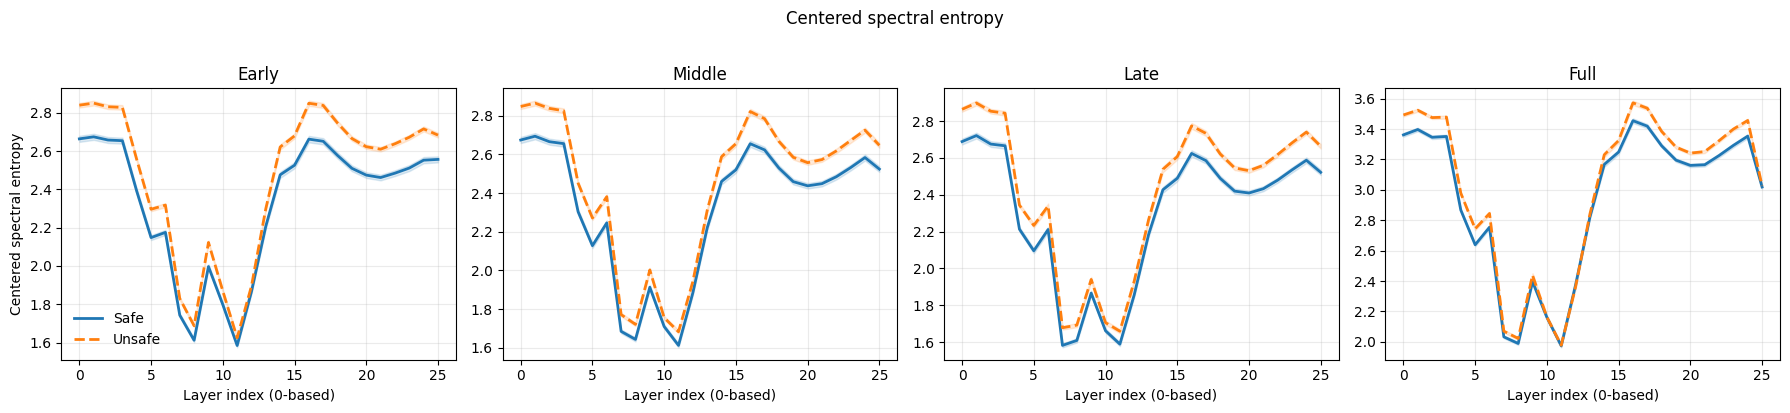

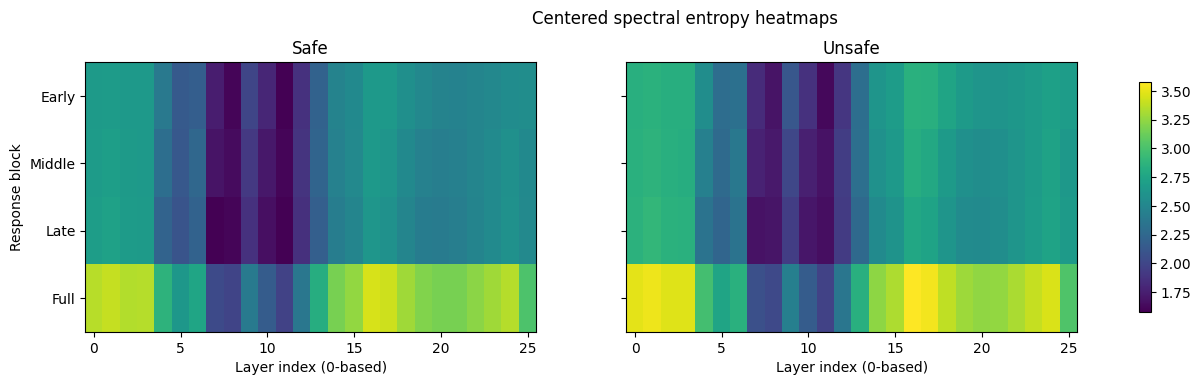

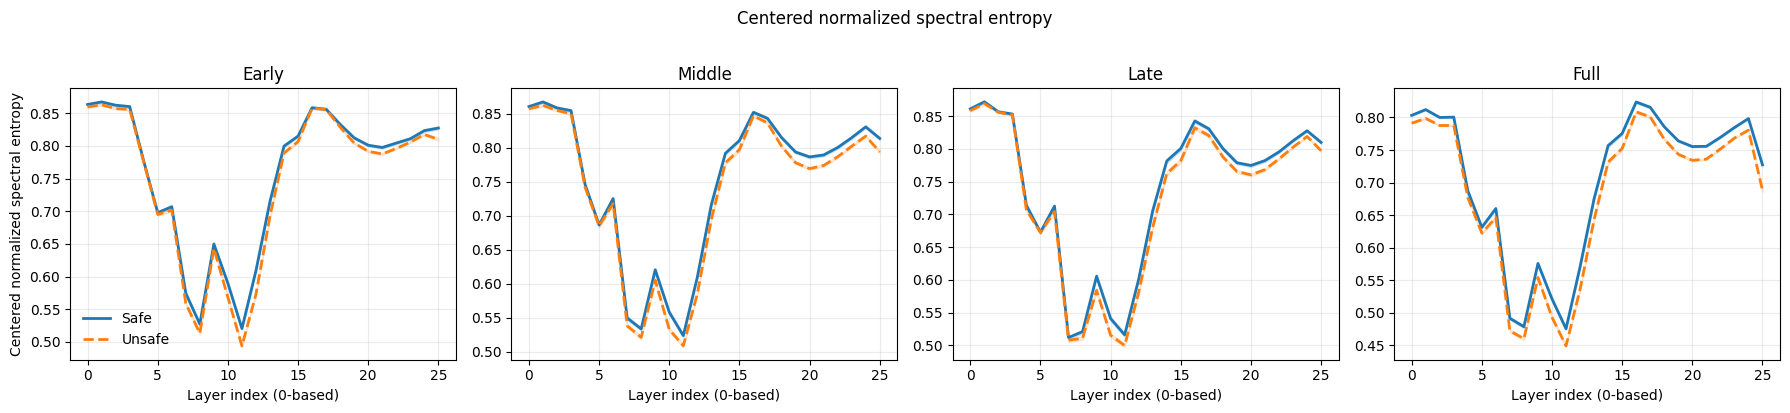

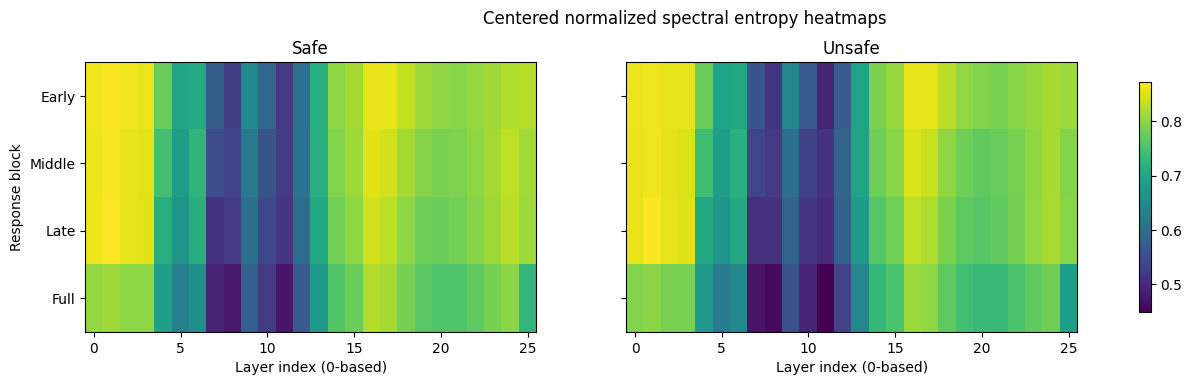

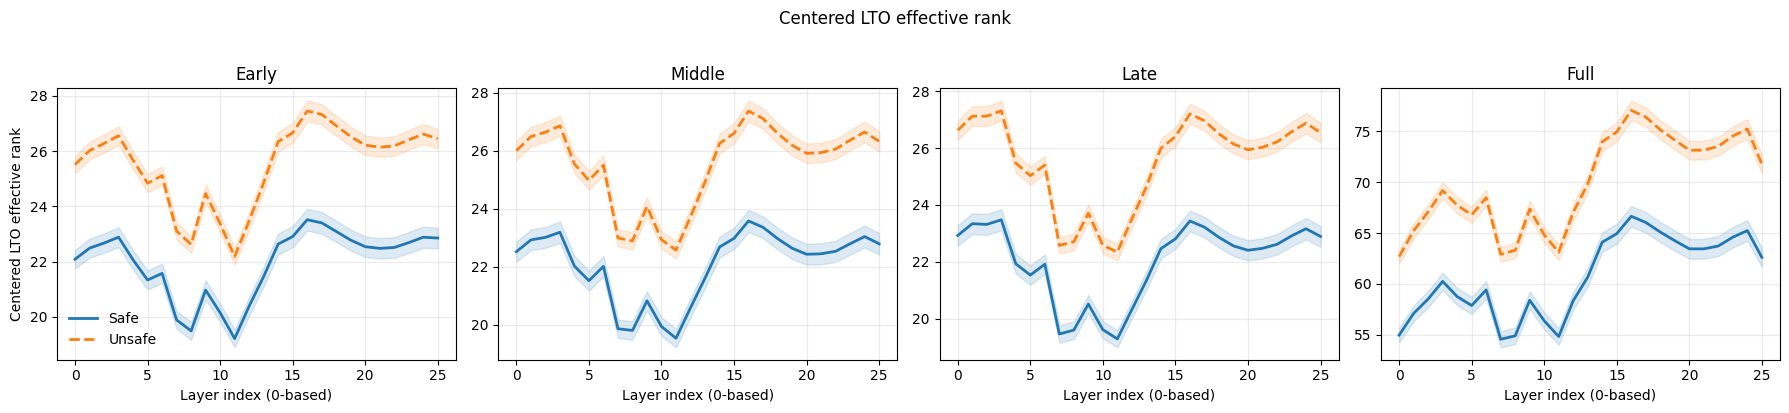

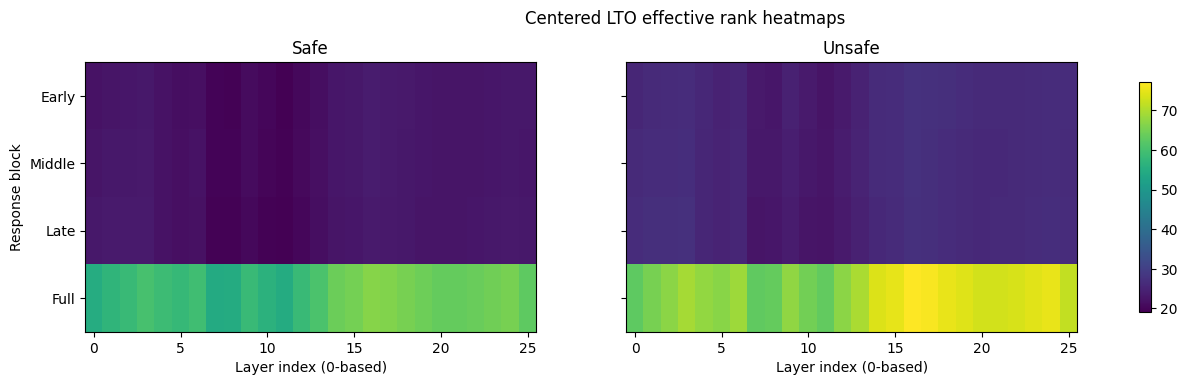

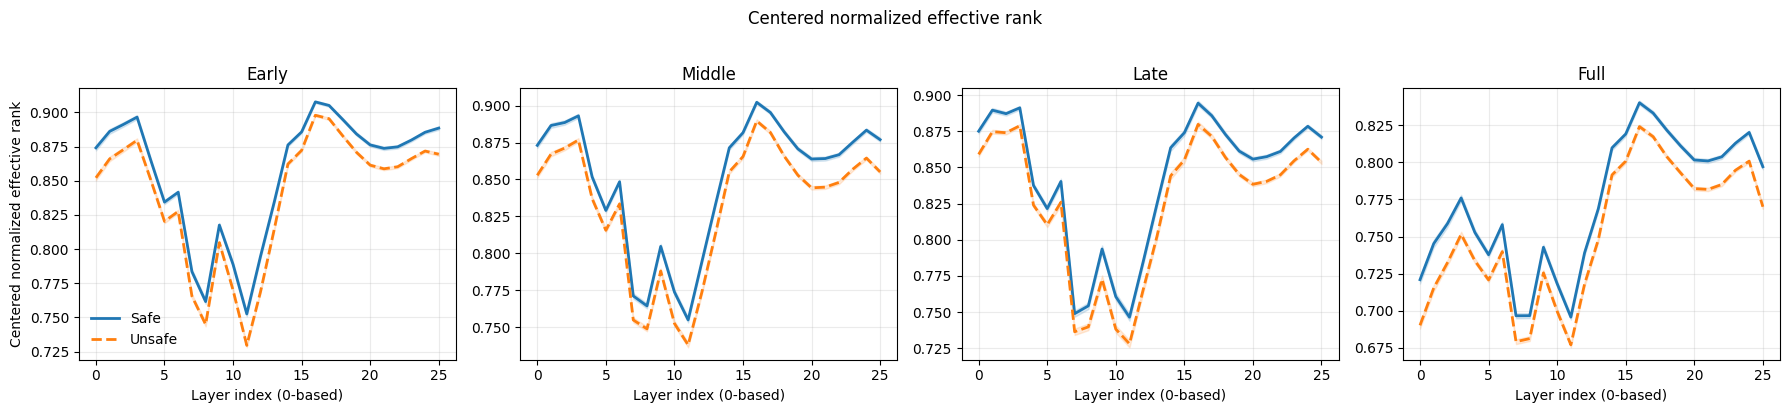

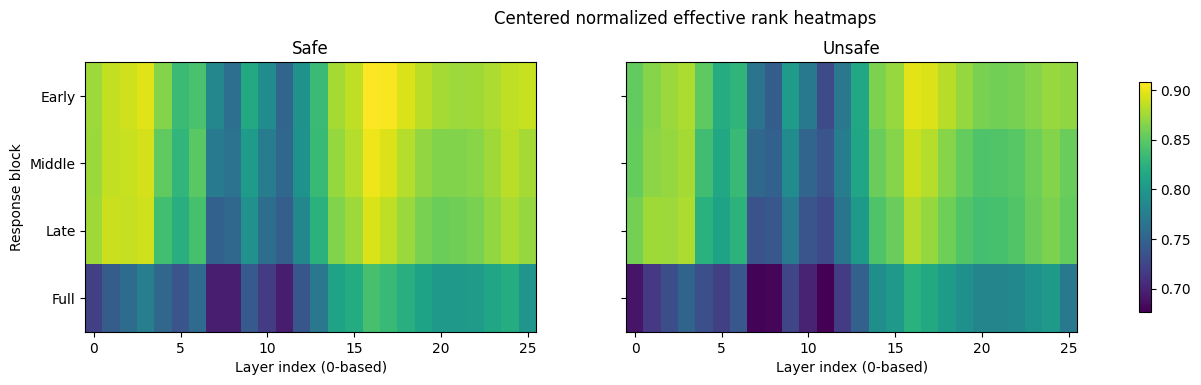

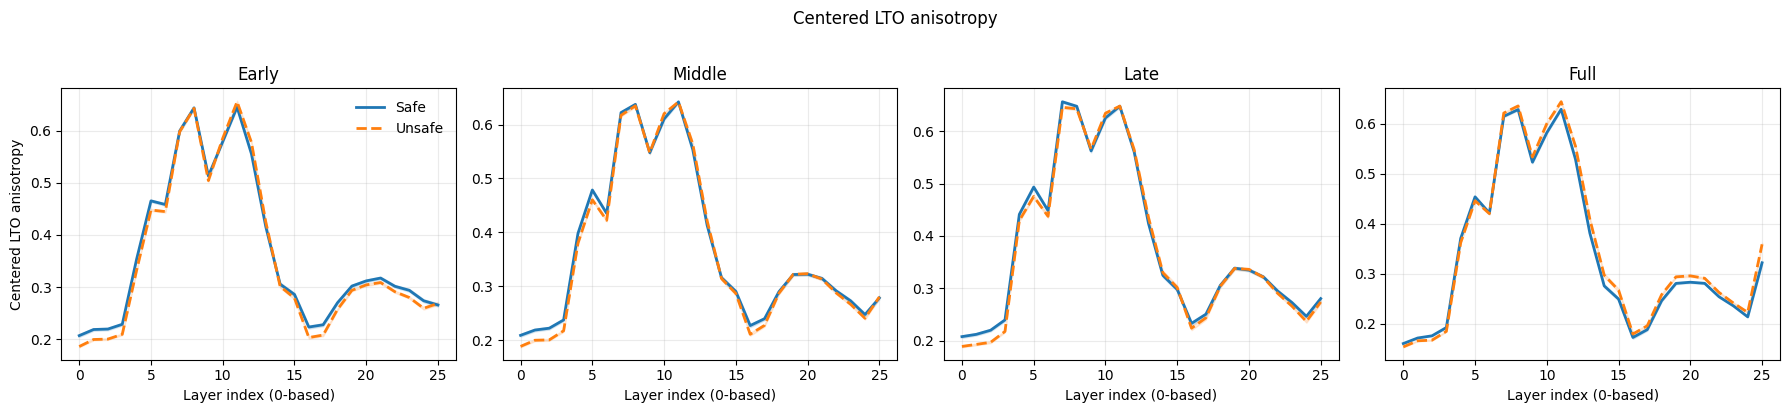

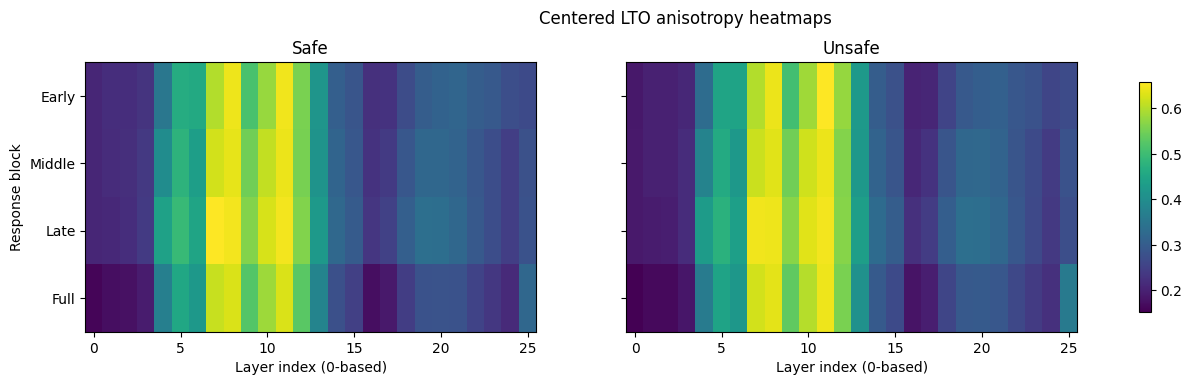

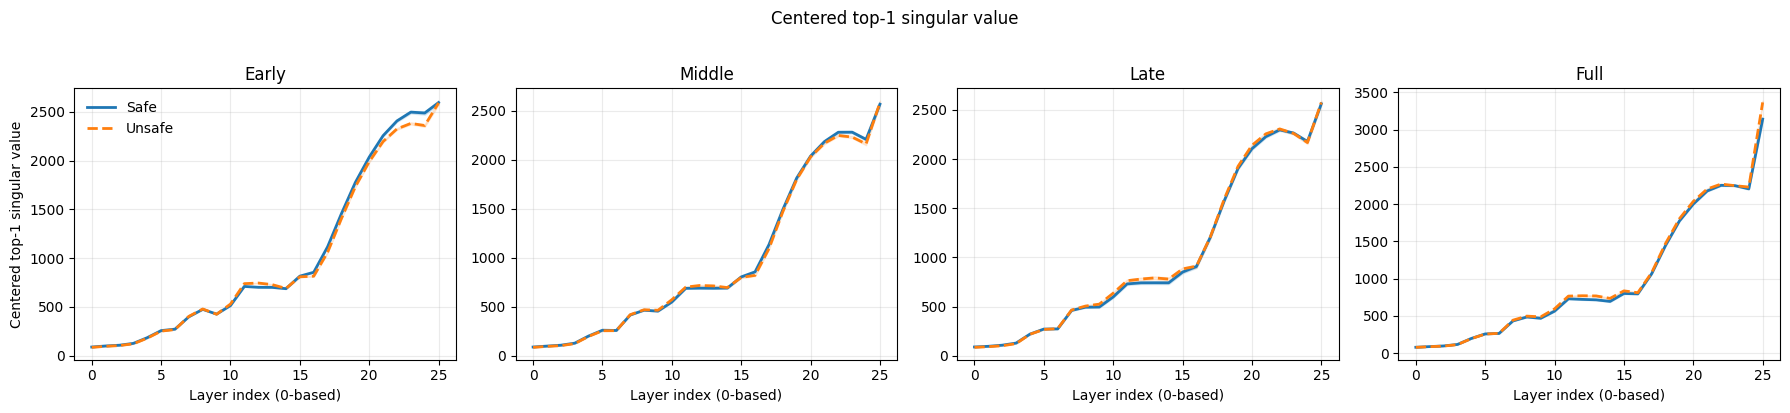

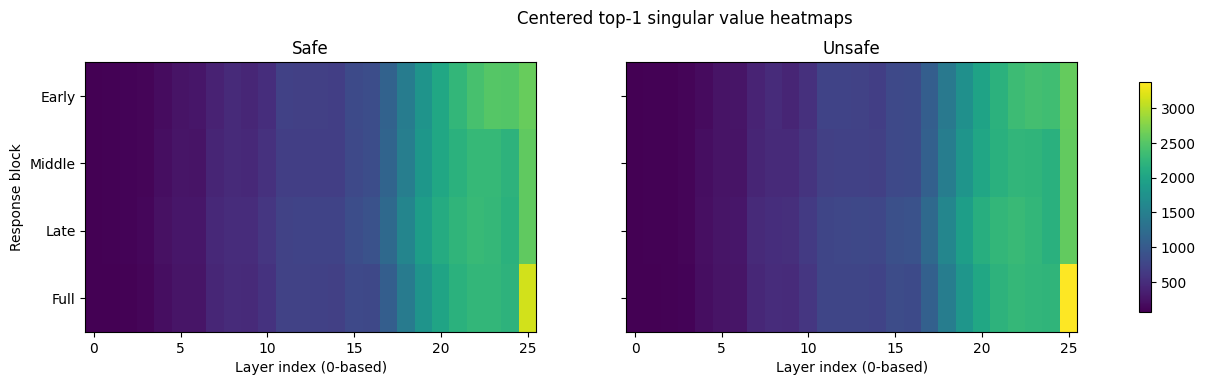

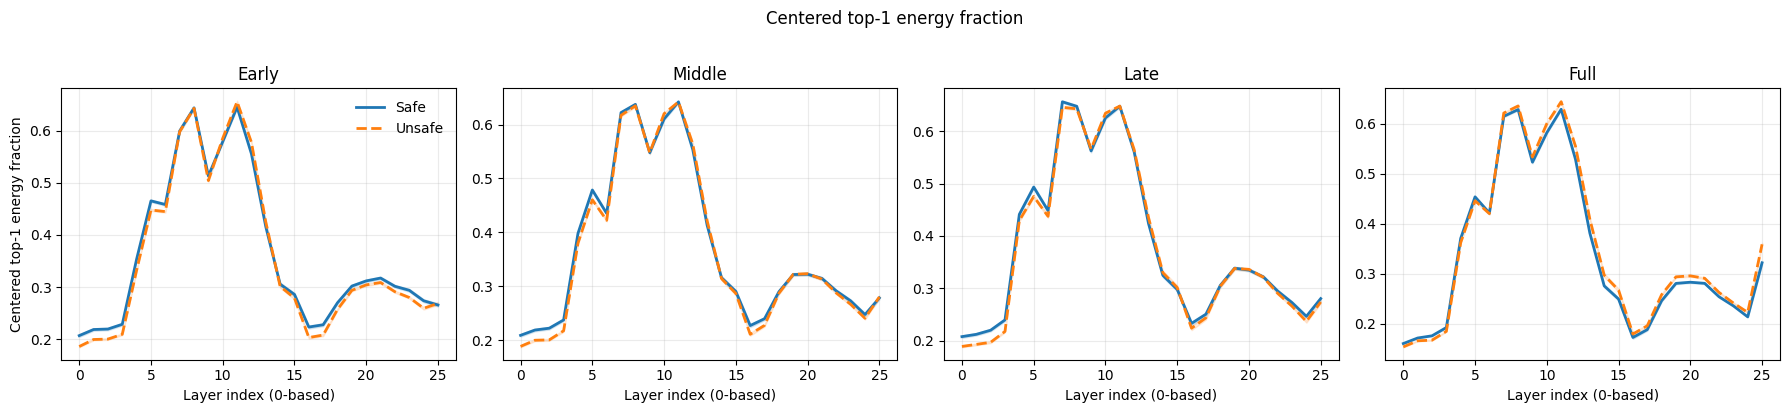

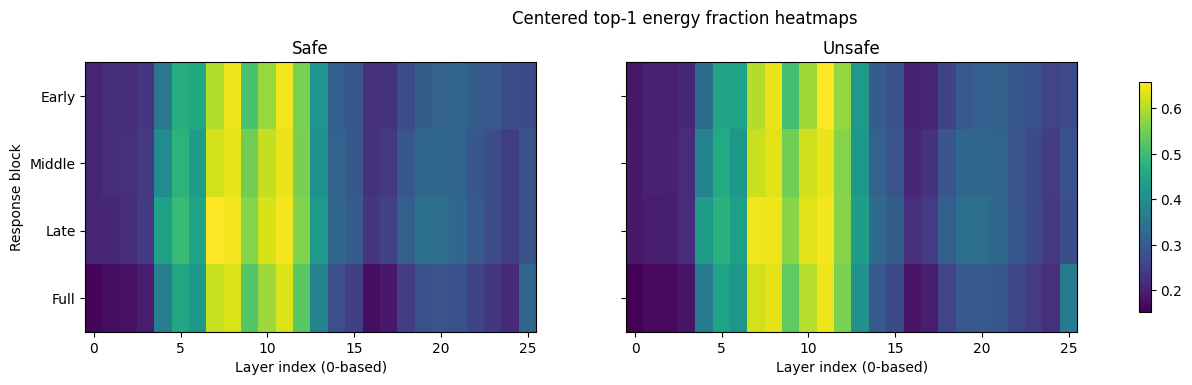

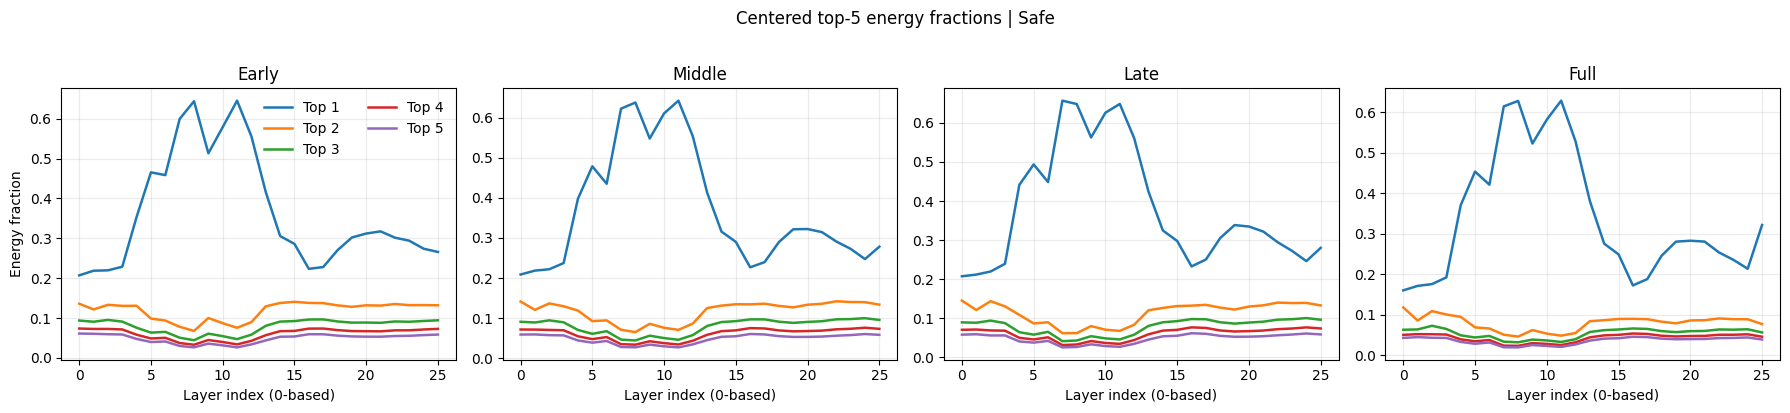

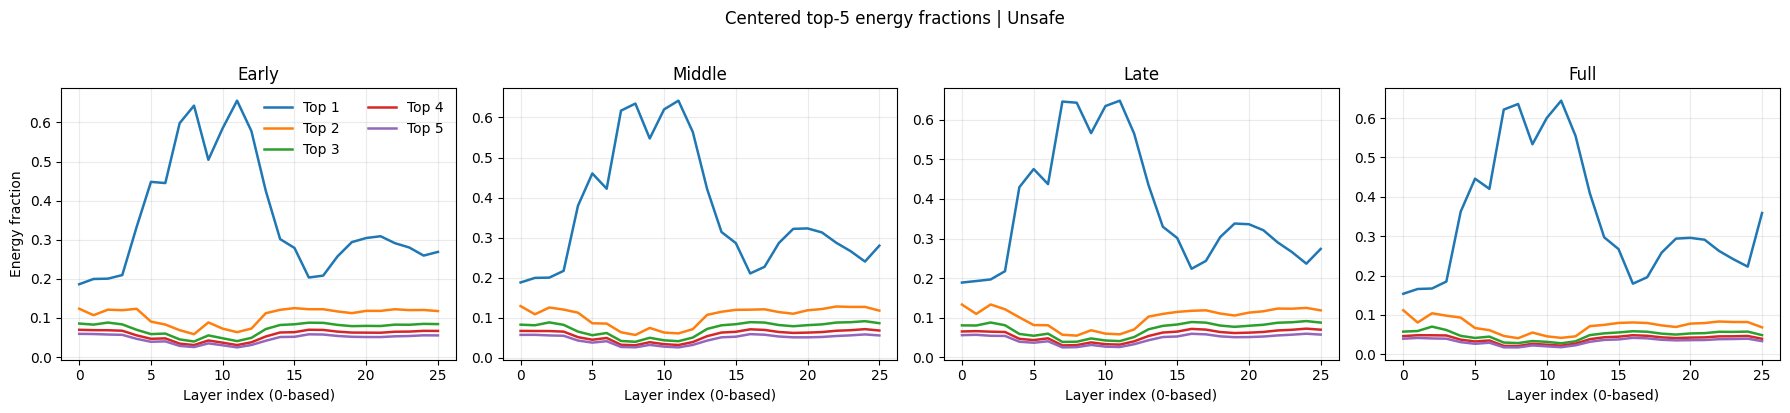

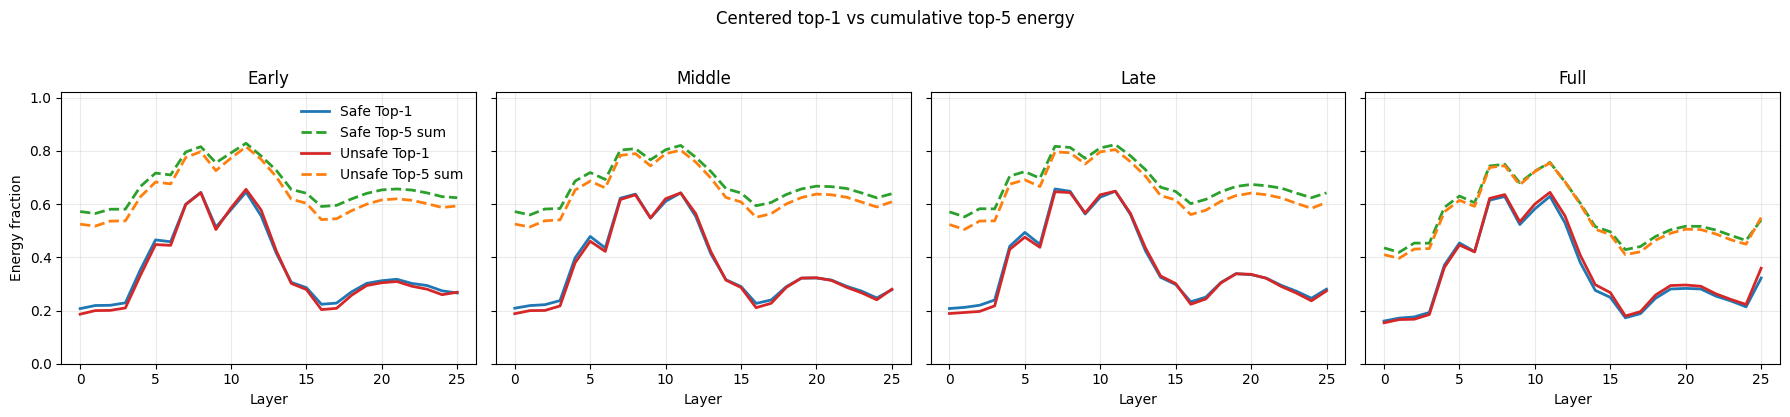

Uncentered rows: 1038206


,phase,layer,tokens,spectral_entropy,normalized_spectral_entropy,lto_effective_rank,normalized_effective_rank,anisotropy,top1_singular_value,energy_fraction_1,energy_fraction_2,energy_fraction_3,energy_fraction_4,energy_fraction_5,prompt_id,rollout_key,rollout_id,label
0,early,0,32,1.484467,0.428327,19.732950,0.616655,0.697995,1571.644165,0.697995,0.053526,0.035043,0.028924,0.019924,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
1,early,1,32,1.412981,0.407700,19.992773,0.624774,0.720122,1848.279785,0.720122,0.046718,0.029118,0.025184,0.021439,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
2,early,2,32,1.340915,0.386906,20.061775,0.626930,0.738584,2104.035645,0.738584,0.042570,0.033356,0.021584,0.018376,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
3,early,3,32,0.681944,0.196767,15.545913,0.485810,0.887885,3949.886230,0.887885,0.020487,0.011689,0.009094,0.007474,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe
4,early,4,32,0.392031,0.113116,12.225569,0.382049,0.942197,5990.174805,0.942197,0.010698,0.006633,0.004660,0.003546,bd57b45379c93c898ede8a9c49f70bda8970d31fb70196...,s0000_r00,0,Unsafe


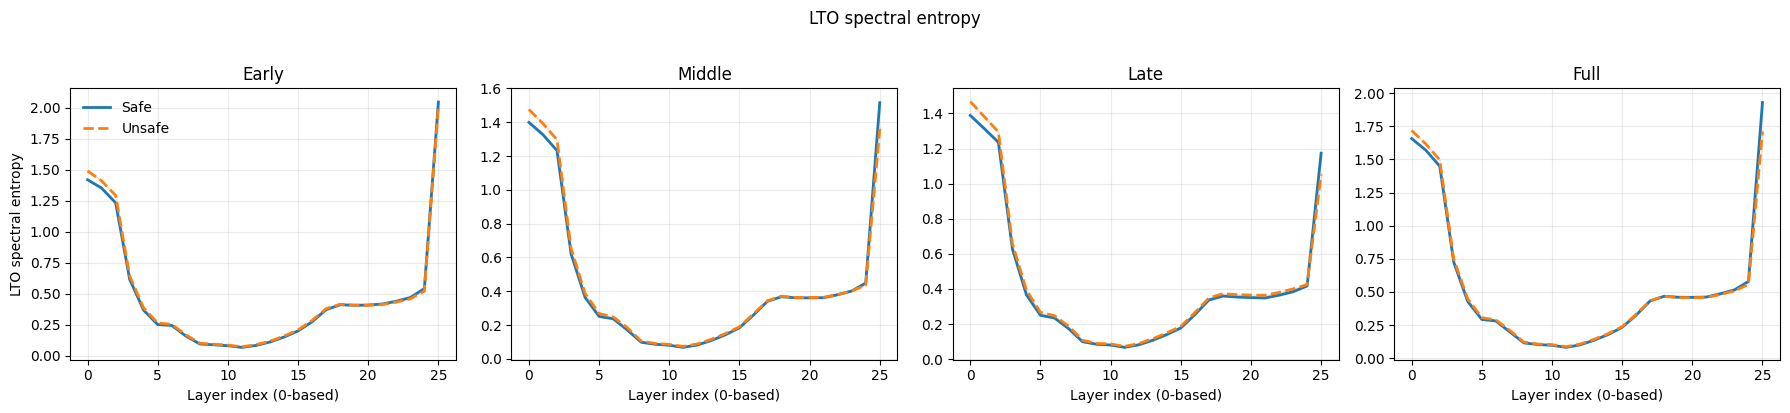

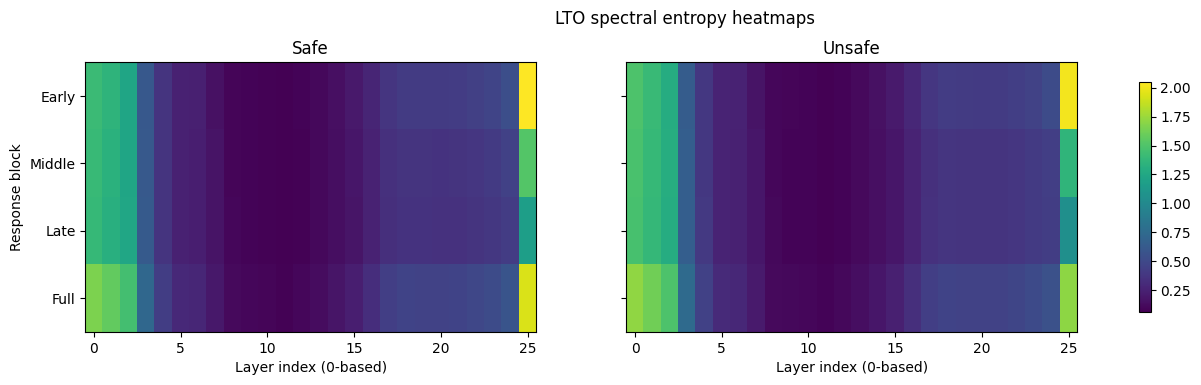

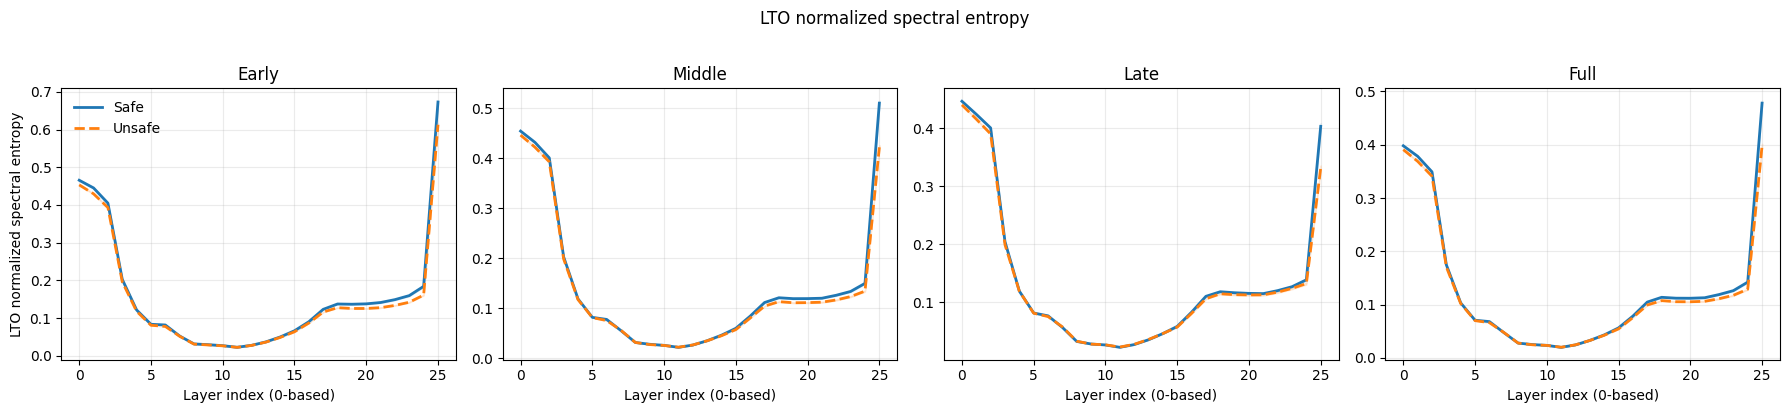

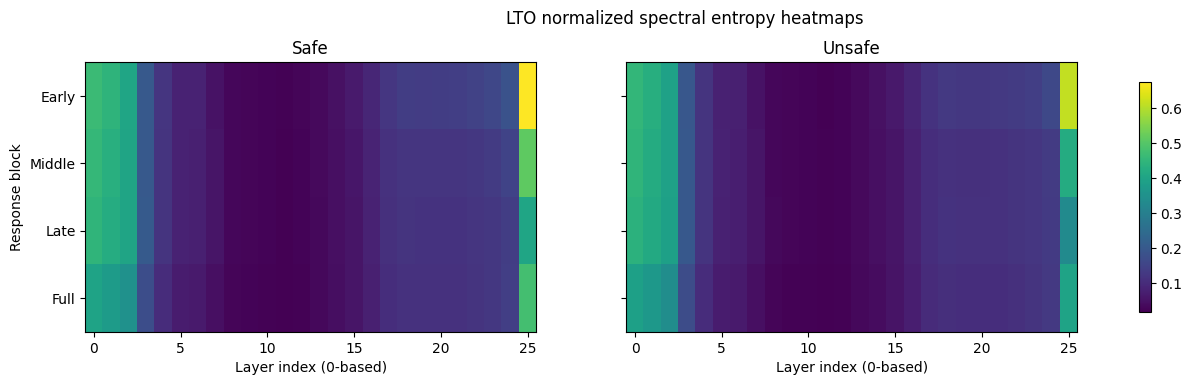

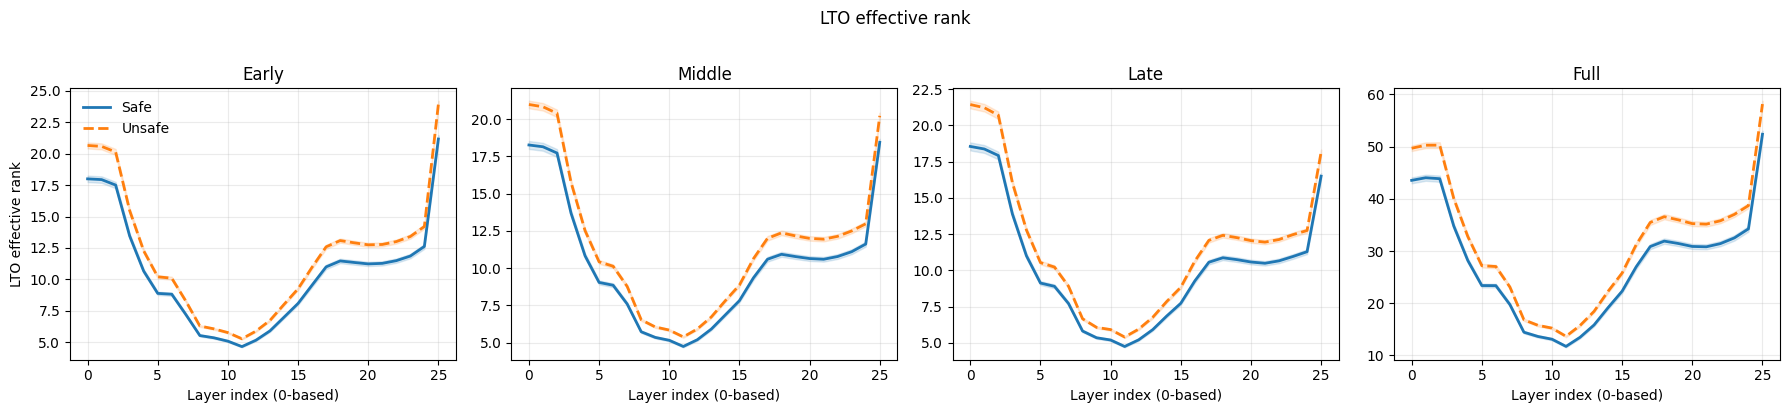

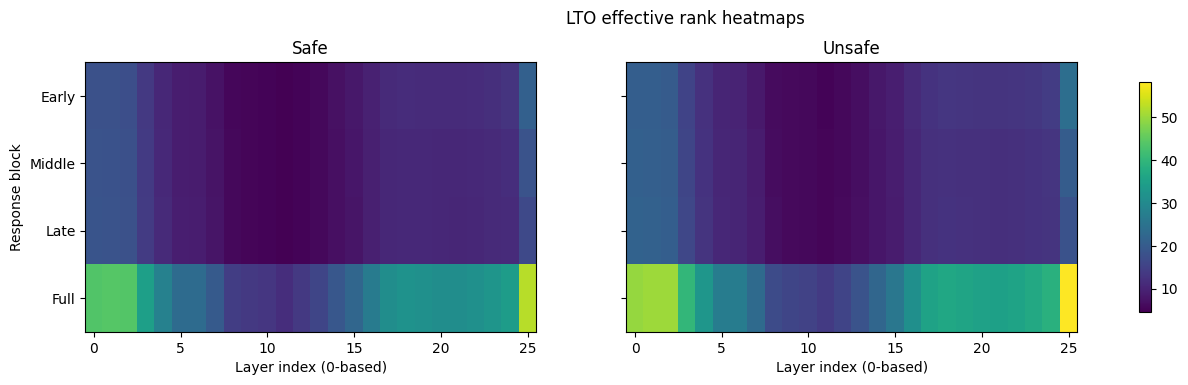

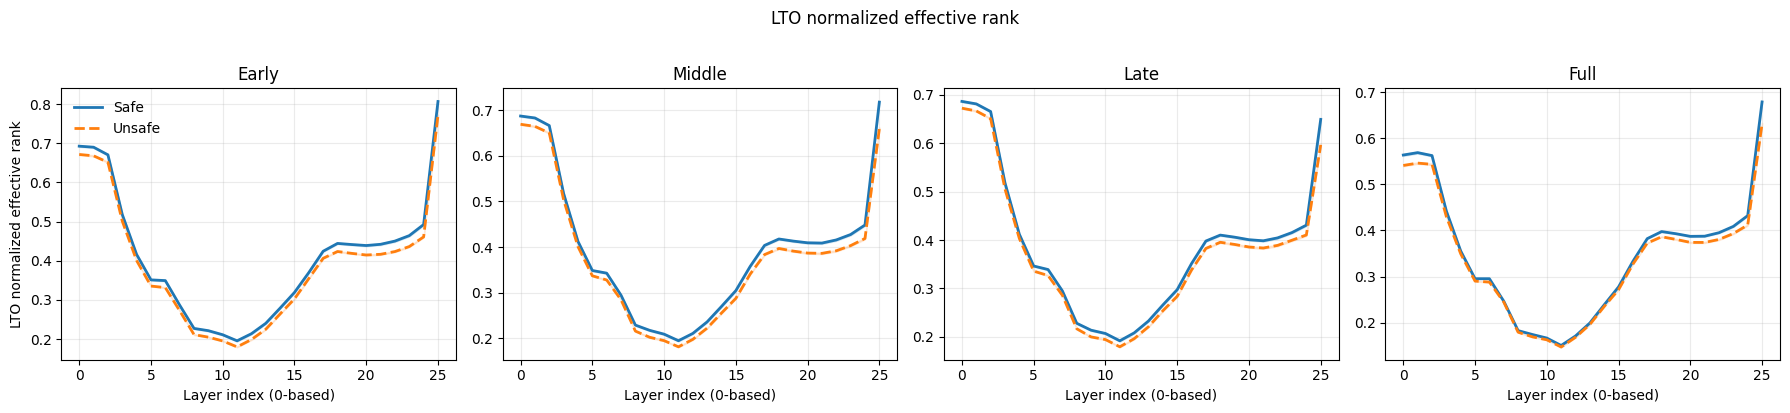

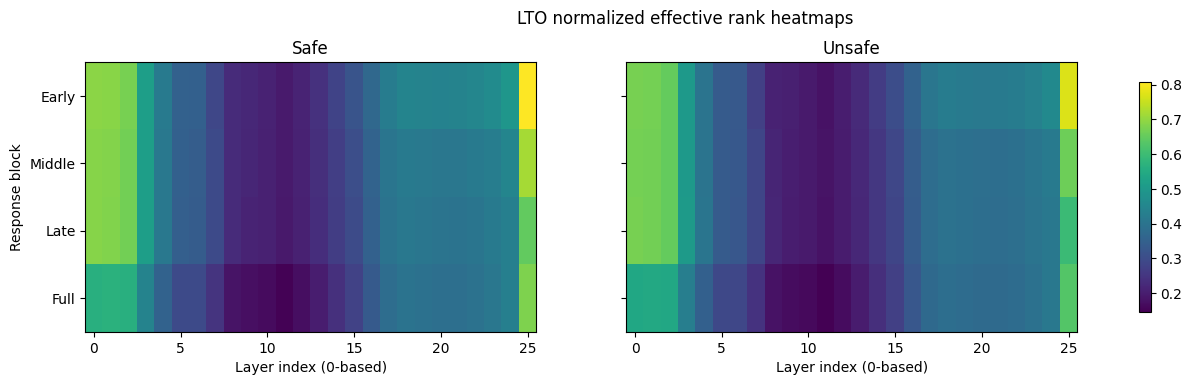

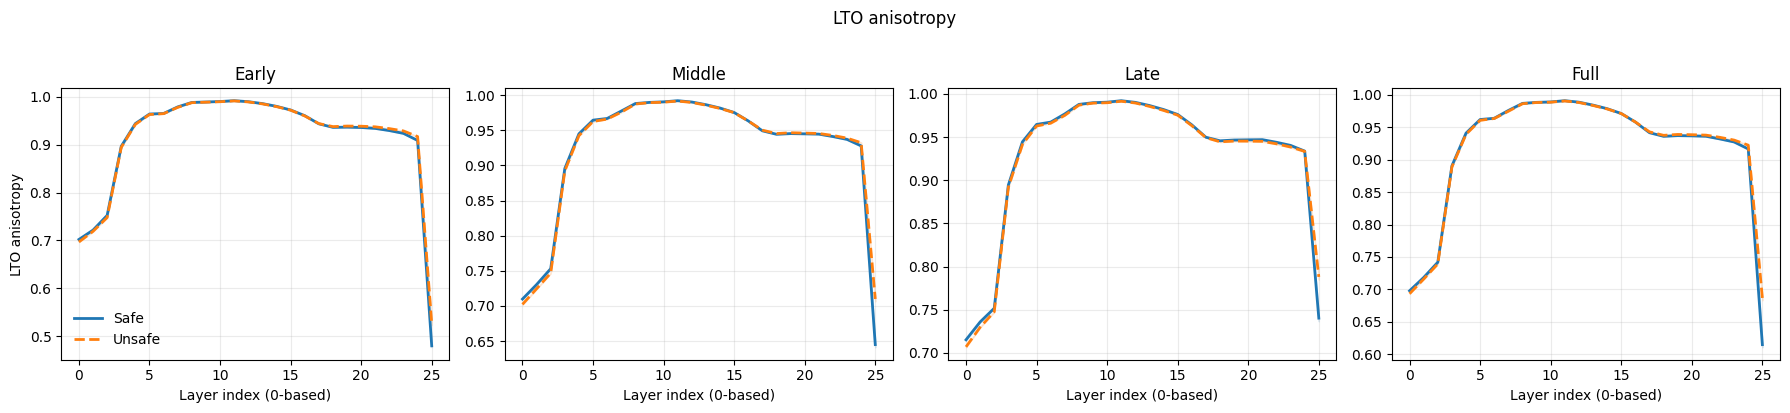

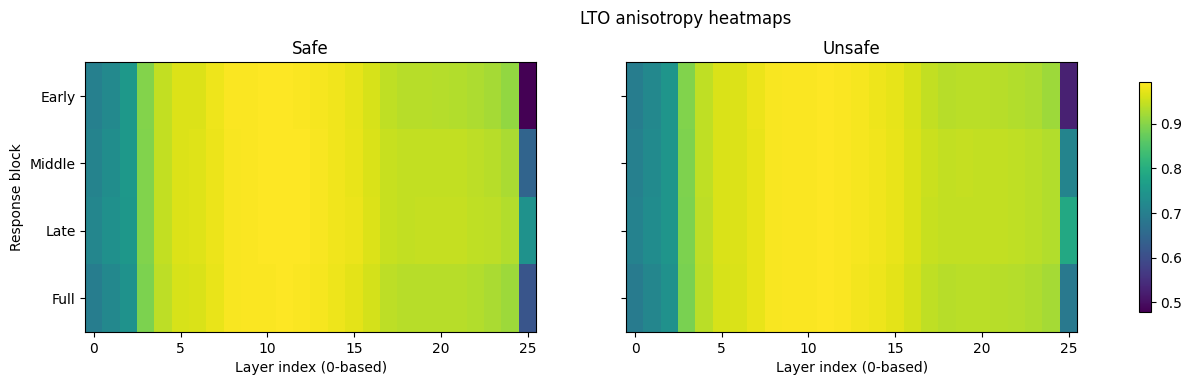

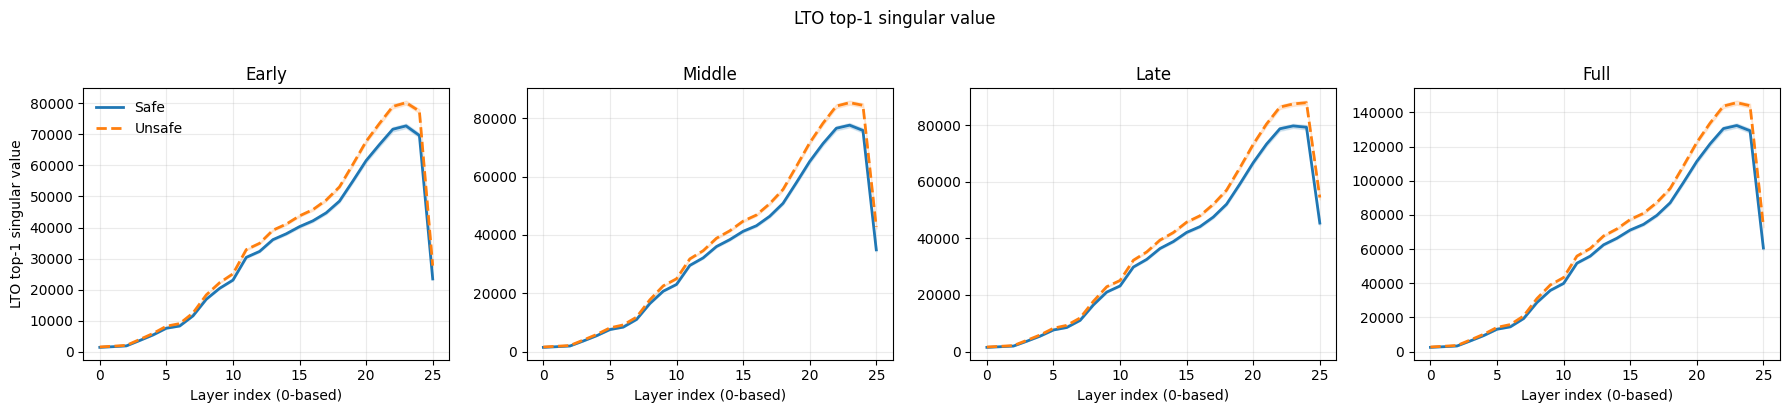

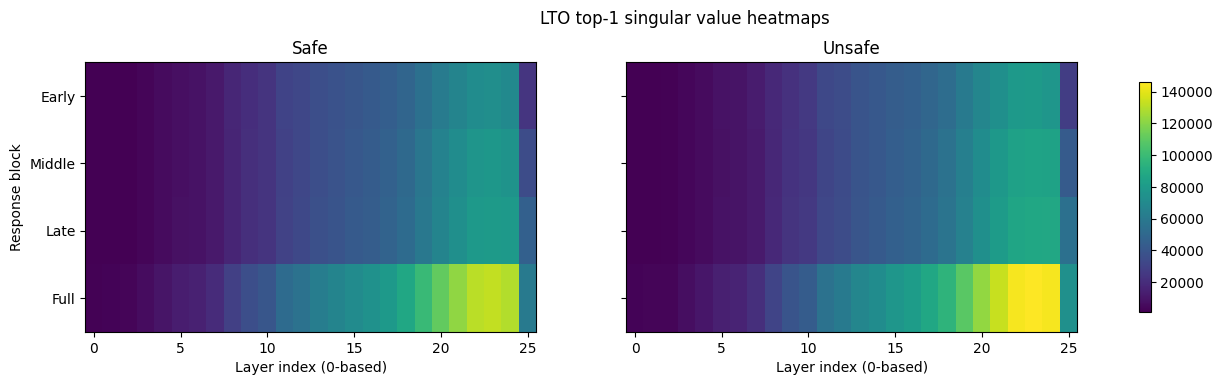

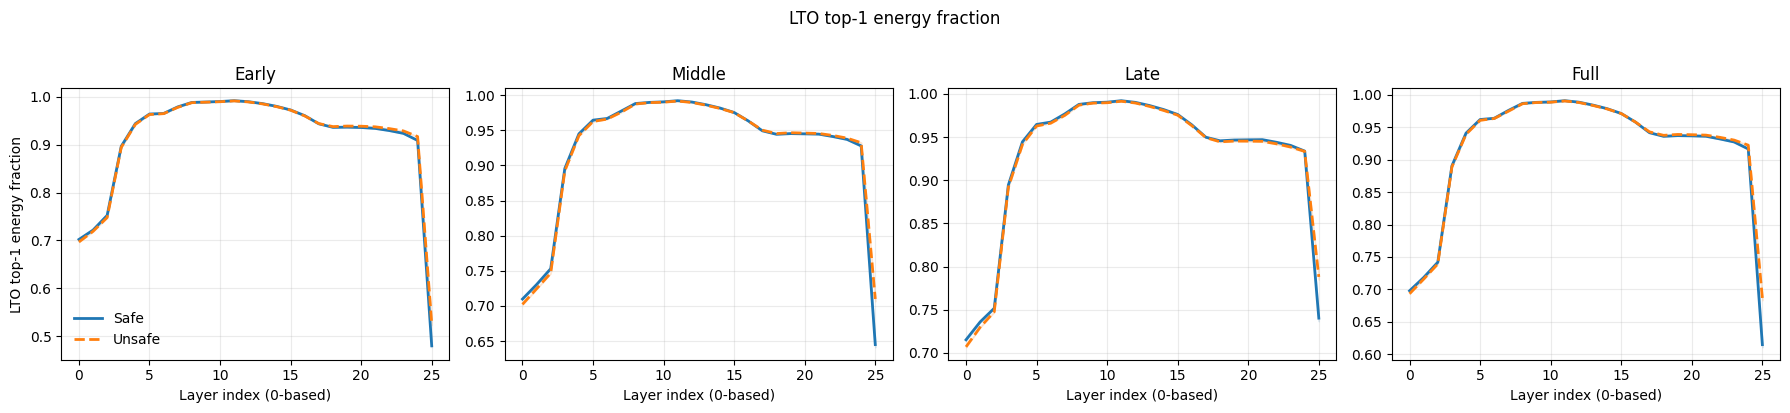

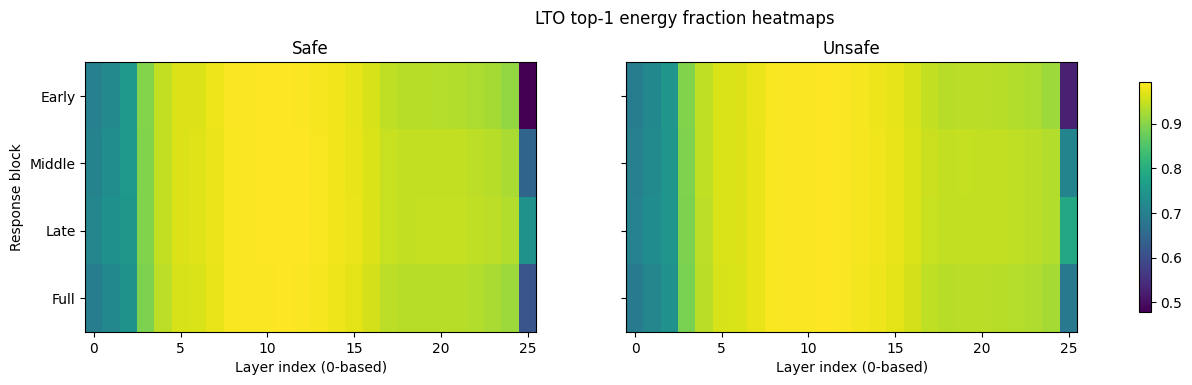

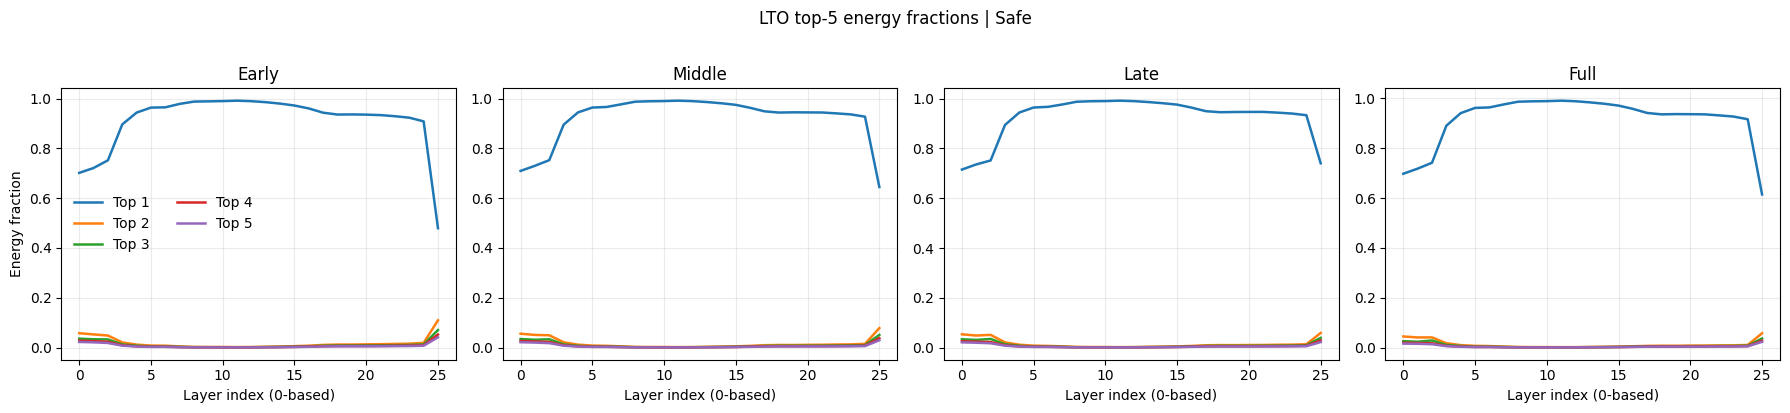

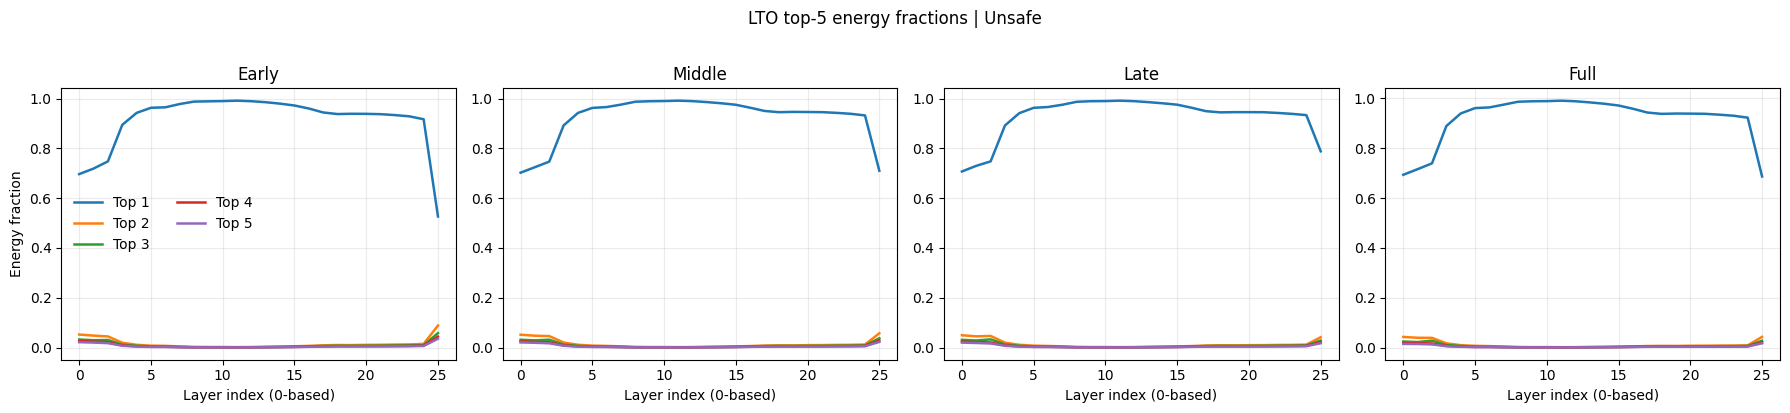

,phase,layer,mean,std,count,ci95,ci95_low,ci95_high,mode,metric
0,early,0,0.173968,0.548218,4970,0.015242,0.158726,0.189209,centered,spectral_entropy
1,early,1,0.174054,0.552563,4970,0.015362,0.158692,0.189417,centered,spectral_entropy
2,early,2,0.171678,0.541719,4970,0.015061,0.156617,0.186739,centered,spectral_entropy
3,early,3,0.171947,0.541485,4970,0.015054,0.156892,0.187001,centered,spectral_entropy
4,early,4,0.163589,0.469384,4970,0.013050,0.150539,0.176639,centered,spectral_entropy
5,early,5,0.146970,0.450968,4970,0.012538,0.134432,0.159508,centered,spectral_entropy
6,early,6,0.141207,0.479080,4970,0.013319,0.127887,0.154526,centered,spectral_entropy
7,early,7,0.085908,0.377934,4970,0.010507,0.075400,0.096415,centered,spectral_entropy
8,early,8,0.075078,0.397499,4970,0.011051,0.064027,0.086129,centered,spectral_entropy
9,early,9,0.124930,0.453988,4970,0.012622,0.112308,0.137551,centered,spectral_entropy


Centered metrics: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/analysis_safety_spectral_v1/all_prompts/centered_metrics.parquet
Uncentered metrics: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/analysis_safety_spectral_v1/all_prompts/uncentered_metrics.parquet
Figures: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/analysis_safety_spectral_v1/all_prompts/figures
Chunk cache: /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs/analysis_safety_spectral_v1/all_prompts/metric_cache


<Figure size 640x480 with 0 Axes>

In [12]:
%run /content/gemma3_pku_saferlhf_analysis.py --run-root /content/drive/MyDrive/gemma3_1b_it_gsm8k_raw26_v3_lean/pku_saferlhf_existing_responses/response_token_positions/full_5000_pairs